In [3]:
## Nome do estudante:
- (Artur Ponce de Leon Arruda)

SyntaxError: invalid syntax. Perhaps you forgot a comma? (3162262375.py, line 2)

In [4]:
from google.colab import files

# Abre a janela para enviar o arquivo CSV da base de dados
uploaded = files.upload()

Saving dataset_jornalismo_esportivo_segunda_chamada (2).csv to dataset_jornalismo_esportivo_segunda_chamada (2).csv


In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Lê o arquivo enviado
df = pd.read_csv(list(uploaded.keys())[0])

# Guarda uma cópia da base original
df_original = df.copy()

# Cinco primeiras linhas
display(df.head())

# Quantidade de registros e de variáveis
print(df.shape)

# Tipos das colunas e valores preenchidos
df.info()

,data_publicacao,portal,titulo,modalidade,tipo_conteudo,turno_publicacao,visualizacoes,usuarios_unicos,tempo_medio_segundos,curtidas,comentarios,compartilhamentos,cliques_relacionados,novos_assinantes,receita_publicitaria
0,2026-10-01,Site,Clássico nacional movimenta a rodada,Futebol,Notícia,Manhã,52000,43000,78.0,1200,180,310,4100,145,4300
1,2026-10-01,Site,Como o basquete mudou sua defesa,Basquete,Análise,Tarde,28000,22500,150.0,720,140,260,2300,92,2500
2,2026-10-01,YouTube,Capitã fala sobre preparação para a final,Vôlei,Entrevista,Noite,18000,14500,275.0,980,195,410,1900,105,2300
3,2026-10-01,Site,Bastidores da equipe antes do grande prêmio,Automobilismo,Reportagem,Tarde,24000,19500,220.0,650,120,300,2500,120,3800
4,2026-10-05,YouTube,Os melhores lances do fim de semana,Futebol,Vídeo,Noite,68000,55000,210.0,2600,350,620,5300,190,5200


(24, 15)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 24 entries, 0 to 23
Data columns (total 15 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   data_publicacao       24 non-null     object 
 1   portal                24 non-null     object 
 2   titulo                24 non-null     object 
 3   modalidade            24 non-null     object 
 4   tipo_conteudo         24 non-null     object 
 5   turno_publicacao      24 non-null     object 
 6   visualizacoes         24 non-null     int64  
 7   usuarios_unicos       24 non-null     int64  
 8   tempo_medio_segundos  23 non-null     float64
 9   curtidas              24 non-null     int64  
 10  comentarios           24 non-null     int64  
 11  compartilhamentos     24 non-null     int64  
 12  cliques_relacionados  24 non-null     int64  
 13  novos_assinantes      24 non-null     int64  
 14  receita_publicitaria  24 non-null     int64  
dtypes: float64(1), i

### Análise inicial dos dados

A base de dados foi importada com a biblioteca Pandas e foi guardada uma cópia da base original em `df_original`. Em seguida, foram usadas as funções `head()`, `shape` e `info()` para visualizar os primeiros registros e verificar a estrutura da base.

A base possui **24 registros e 15 variáveis**. As colunas `data_publicacao`, `portal`, `titulo`, `modalidade`, `tipo_conteudo` e `turno_publicacao` foram lidas como texto, e as demais são numéricas (`int64` e `float64`). A coluna `tempo_medio_segundos` tem 23 valores preenchidos, o que indica **um valor ausente**.

In [6]:
# Mostra o registro que tem valor ausente
df[df["tempo_medio_segundos"].isna()]

,data_publicacao,portal,titulo,modalidade,tipo_conteudo,turno_publicacao,visualizacoes,usuarios_unicos,tempo_medio_segundos,curtidas,comentarios,compartilhamentos,cliques_relacionados,novos_assinantes,receita_publicitaria
19,2026-10-17,YouTube,Piloto comenta disputa pelo pódio,Automobilismo,Entrevista,Noite,23000,18500,NaN,820,145,350,2600,130,3900


### Análise do valor ausente

O valor ausente está na coluna `tempo_medio_segundos` do conteúdo "Piloto comenta disputa pelo pódio" (automobilismo, entrevista, YouTube). As outras informações desse conteúdo estão preenchidas. O valor não foi substituído por zero, porque zero significaria que ninguém permaneceu no conteúdo, e não que o tempo deixou de ser registrado.

In [7]:
# Categorias da coluna modalidade
df["modalidade"].unique()

array(['Futebol', 'Basquete', 'Vôlei', 'Automobilismo', 'Vôlei '],
      dtype=object)

### Verificação de inconsistências

Ao verificar os valores únicos da coluna `modalidade`, foi encontrada uma inconsistência: `Vôlei` e `Vôlei ` aparecem como categorias diferentes, por causa de um espaço extra no final. O Pandas trataria as duas como modalidades diferentes.

In [8]:
# Verifica registros duplicados
print("Duplicados:", df.duplicated().sum())

# Quantidade de valores ausentes por coluna
print(df.isna().sum())

Duplicados: 0
data_publicacao         0
portal                  0
titulo                  0
modalidade              0
tipo_conteudo           0
turno_publicacao        0
visualizacoes           0
usuarios_unicos         0
tempo_medio_segundos    1
curtidas                0
comentarios             0
compartilhamentos       0
cliques_relacionados    0
novos_assinantes        0
receita_publicitaria    0
dtype: int64


A verificação de duplicados retornou zero, então não há registros repetidos na base. A contagem de ausentes confirma um único valor ausente, na coluna `tempo_medio_segundos`.

In [9]:
# Cópia de trabalho: o tratamento é feito em "dados"
dados = df.copy()

# Remove o espaço extra do nome da modalidade
dados["modalidade"] = dados["modalidade"].str.strip()

# Converte a data de publicação para o formato de data
dados["data_publicacao"] = pd.to_datetime(dados["data_publicacao"], errors="coerce")

print(dados["modalidade"].unique())
print(dados["data_publicacao"].dtype)

['Futebol' 'Basquete' 'Vôlei' 'Automobilismo']
datetime64[ns]


### Tratamento dos dados

O tratamento foi feito na cópia `dados`. O método `.str.strip()` removeu o espaço extra, e agora existem apenas quatro modalidades: Futebol, Basquete, Vôlei e Automobilismo. A coluna `data_publicacao` foi convertida para o formato de data com `pd.to_datetime()`. O valor ausente foi mantido.

In [10]:
# Total de interações
dados["total_interacoes"] = dados["curtidas"] + dados["comentarios"] + dados["compartilhamentos"]

# Divisão segura: o zero no denominador vira NaN para não gerar valores infinitos
visualizacoes = dados["visualizacoes"].replace(0, np.nan)
cliques = dados["cliques_relacionados"].replace(0, np.nan)
usuarios = dados["usuarios_unicos"].replace(0, np.nan)

# Métricas
dados["taxa_engajamento_pct"] = dados["total_interacoes"] / visualizacoes * 100
dados["taxa_recirculacao_pct"] = dados["cliques_relacionados"] / visualizacoes * 100
dados["taxa_conversao_pct"] = dados["novos_assinantes"] / cliques * 100
dados["rpm"] = dados["receita_publicitaria"] / visualizacoes * 1000
dados["frequencia_media"] = dados["visualizacoes"] / usuarios

dados.head()

,data_publicacao,portal,titulo,modalidade,tipo_conteudo,turno_publicacao,visualizacoes,usuarios_unicos,tempo_medio_segundos,curtidas,...,compartilhamentos,cliques_relacionados,novos_assinantes,receita_publicitaria,total_interacoes,taxa_engajamento_pct,taxa_recirculacao_pct,taxa_conversao_pct,rpm,frequencia_media
0,2026-10-01,Site,Clássico nacional movimenta a rodada,Futebol,Notícia,Manhã,52000,43000,78.0,1200,...,310,4100,145,4300,1690,3.250000,7.884615,3.536585,82.692308,1.209302
1,2026-10-01,Site,Como o basquete mudou sua defesa,Basquete,Análise,Tarde,28000,22500,150.0,720,...,260,2300,92,2500,1120,4.000000,8.214286,4.000000,89.285714,1.244444
2,2026-10-01,YouTube,Capitã fala sobre preparação para a final,Vôlei,Entrevista,Noite,18000,14500,275.0,980,...,410,1900,105,2300,1585,8.805556,10.555556,5.526316,127.777778,1.241379
3,2026-10-01,Site,Bastidores da equipe antes do grande prêmio,Automobilismo,Reportagem,Tarde,24000,19500,220.0,650,...,300,2500,120,3800,1070,4.458333,10.416667,4.800000,158.333333,1.230769
4,2026-10-05,YouTube,Os melhores lances do fim de semana,Futebol,Vídeo,Noite,68000,55000,210.0,2600,...,620,5300,190,5200,3570,5.250000,7.794118,3.584906,76.470588,1.236364


### Cálculo das métricas

Foram criadas as cinco métricas pedidas: **taxa de engajamento, taxa de recirculação, taxa de conversão, RPM e frequência média**. Para evitar valores infinitos, foi usada a divisão segura: antes de dividir, o valor zero do denominador é trocado por `NaN`. As métricas foram adicionadas como novas colunas, o que permite analisar cada conteúdo individualmente.

In [11]:
# Métricas do primeiro conteúdo da base
dados.loc[0, ["titulo", "taxa_engajamento_pct", "taxa_recirculacao_pct", "taxa_conversao_pct", "rpm", "frequencia_media"]]

,0
titulo,Clássico nacional movimenta a rodada
taxa_engajamento_pct,3.25
taxa_recirculacao_pct,7.884615
taxa_conversao_pct,3.536585
rpm,82.692308
frequencia_media,1.209302


In [12]:
# Soma dos valores por modalidade
agrupado_modalidade = dados.groupby("modalidade")[["visualizacoes", "usuarios_unicos", "total_interacoes",
                                                    "cliques_relacionados", "novos_assinantes", "receita_publicitaria"]].sum()

# Métricas recalculadas a partir das somas
agrupado_modalidade["taxa_engajamento_pct"] = agrupado_modalidade["total_interacoes"] / agrupado_modalidade["visualizacoes"] * 100
agrupado_modalidade["taxa_recirculacao_pct"] = agrupado_modalidade["cliques_relacionados"] / agrupado_modalidade["visualizacoes"] * 100
agrupado_modalidade["taxa_conversao_pct"] = agrupado_modalidade["novos_assinantes"] / agrupado_modalidade["cliques_relacionados"] * 100
agrupado_modalidade["rpm"] = agrupado_modalidade["receita_publicitaria"] / agrupado_modalidade["visualizacoes"] * 1000
agrupado_modalidade["frequencia_media"] = agrupado_modalidade["visualizacoes"] / agrupado_modalidade["usuarios_unicos"]

agrupado_modalidade

,visualizacoes,usuarios_unicos,total_interacoes,cliques_relacionados,novos_assinantes,receita_publicitaria,taxa_engajamento_pct,taxa_recirculacao_pct,taxa_conversao_pct,rpm,frequencia_media
modalidade,,,,,,,,,,,
Automobilismo,149000,121000,7120,16100,793,24400,4.778523,10.805369,4.925466,163.758389,1.231405
Basquete,171000,139000,8290,14400,617,17100,4.847953,8.421053,4.284722,100.000000,1.230216
Futebol,324000,266500,15240,25800,975,26500,4.703704,7.962963,3.779070,81.790123,1.215760
Vôlei,125500,100800,11615,12950,692,15400,9.254980,10.318725,5.343629,122.709163,1.245040


In [13]:
# Soma dos valores por tipo de conteúdo
agrupado_tipo = dados.groupby("tipo_conteudo")[["visualizacoes", "usuarios_unicos", "total_interacoes",
                                                 "cliques_relacionados", "novos_assinantes", "receita_publicitaria"]].sum()

# Métricas recalculadas a partir das somas
agrupado_tipo["taxa_engajamento_pct"] = agrupado_tipo["total_interacoes"] / agrupado_tipo["visualizacoes"] * 100
agrupado_tipo["taxa_recirculacao_pct"] = agrupado_tipo["cliques_relacionados"] / agrupado_tipo["visualizacoes"] * 100
agrupado_tipo["taxa_conversao_pct"] = agrupado_tipo["novos_assinantes"] / agrupado_tipo["cliques_relacionados"] * 100
agrupado_tipo["rpm"] = agrupado_tipo["receita_publicitaria"] / agrupado_tipo["visualizacoes"] * 1000
agrupado_tipo["frequencia_media"] = agrupado_tipo["visualizacoes"] / agrupado_tipo["usuarios_unicos"]

# Tempo médio de cada tipo (o valor ausente fica de fora da média)
agrupado_tipo["tempo_medio_segundos"] = dados.groupby("tipo_conteudo")["tempo_medio_segundos"].mean()

agrupado_tipo

,visualizacoes,usuarios_unicos,total_interacoes,cliques_relacionados,novos_assinantes,receita_publicitaria,taxa_engajamento_pct,taxa_recirculacao_pct,taxa_conversao_pct,rpm,frequencia_media,tempo_medio_segundos
tipo_conteudo,,,,,,,,,,,,
Análise,135000,109800,6055,12700,583,15400,4.485185,9.407407,4.590551,114.074074,1.229508,176.000000
Entrevista,114000,92000,7070,11100,530,14100,6.201754,9.736842,4.774775,123.684211,1.239130,273.333333
Notícia,226000,188000,12505,17700,671,18600,5.533186,7.831858,3.790960,82.300885,1.202128,78.000000
Reportagem,139500,112500,7165,13950,683,19100,5.136201,10.000000,4.896057,136.917563,1.240000,237.000000
Vídeo,155000,125000,9470,13800,610,16200,6.109677,8.903226,4.420290,104.516129,1.240000,251.250000


In [14]:
# Soma dos valores por turno de publicação
agrupado_turno = dados.groupby("turno_publicacao")[["visualizacoes", "usuarios_unicos", "total_interacoes",
                                                     "cliques_relacionados", "novos_assinantes", "receita_publicitaria"]].sum()

# Métricas recalculadas a partir das somas
agrupado_turno["taxa_engajamento_pct"] = agrupado_turno["total_interacoes"] / agrupado_turno["visualizacoes"] * 100
agrupado_turno["taxa_recirculacao_pct"] = agrupado_turno["cliques_relacionados"] / agrupado_turno["visualizacoes"] * 100
agrupado_turno["taxa_conversao_pct"] = agrupado_turno["novos_assinantes"] / agrupado_turno["cliques_relacionados"] * 100
agrupado_turno["rpm"] = agrupado_turno["receita_publicitaria"] / agrupado_turno["visualizacoes"] * 1000
agrupado_turno["frequencia_media"] = agrupado_turno["visualizacoes"] / agrupado_turno["usuarios_unicos"]

agrupado_turno

,visualizacoes,usuarios_unicos,total_interacoes,cliques_relacionados,novos_assinantes,receita_publicitaria,taxa_engajamento_pct,taxa_recirculacao_pct,taxa_conversao_pct,rpm,frequencia_media
turno_publicacao,,,,,,,,,,,
Manhã,173000,142500,7670,15600,681,19700,4.433526,9.017341,4.365385,113.872832,1.214035
Noite,308000,248500,18100,28400,1300,34800,5.876623,9.220779,4.577465,112.987013,1.239437
Tarde,288500,236300,16495,25250,1096,28900,5.717504,8.752166,4.340594,100.173310,1.220906


### Agrupamento por modalidade, tipo de conteúdo e turno

Os dados foram agrupados por `modalidade`, `tipo_conteudo` e `turno_publicacao` com `groupby()` e `sum()`. Depois, as métricas foram recalculadas a partir dos totais de cada grupo, sem usar a média simples das taxas de cada conteúdo.

O futebol teve o maior número de visualizações (324.000), mas a menor taxa de engajamento (4,70%), a menor recirculação (7,96%) e a menor conversão (3,78%). O vôlei teve o menor número de visualizações (125.500), mas a maior taxa de engajamento (9,25%) e a maior conversão (5,34%). O automobilismo teve o maior RPM (R$ 163,76). Entre os tipos de conteúdo, a notícia teve mais visualizações (226.000), mas o menor tempo médio (78,0 s) e o menor RPM (R$ 82,30).

In [15]:
# Salva a base tratada e a tabela consolidada por modalidade
dados.to_csv("base_tratada.csv", index=False)
agrupado_modalidade.to_csv("tabela_consolidada_modalidade.csv")

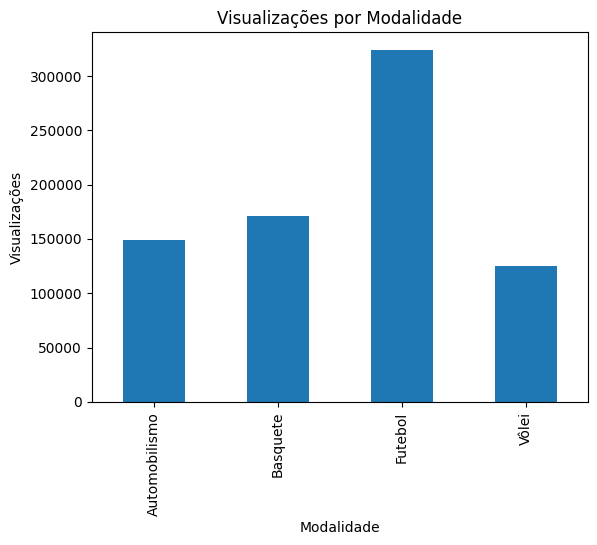

In [16]:
# Gráfico de barras: visualizações por modalidade
agrupado_modalidade["visualizacoes"].plot(kind="bar")

plt.title("Visualizações por Modalidade")
plt.xlabel("Modalidade")
plt.ylabel("Visualizações")
plt.show()

### Análise das Visualizações por Modalidade

O futebol teve o maior número de visualizações (324.000), seguido do basquete (171.000), do automobilismo (149.000) e do vôlei (125.500). O gráfico mostra o volume de público de cada modalidade, mas não mostra a qualidade do consumo: o futebol teve o menor engajamento (4,70%), e o vôlei, o maior (9,25%).

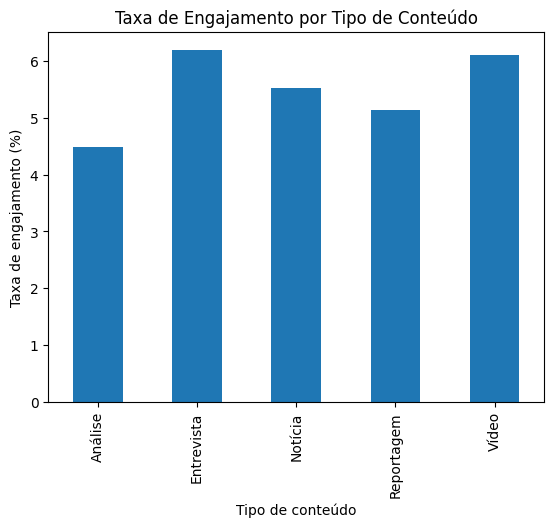

In [17]:
# Gráfico de barras: taxa de engajamento por tipo de conteúdo
agrupado_tipo["taxa_engajamento_pct"].plot(kind="bar")

plt.title("Taxa de Engajamento por Tipo de Conteúdo")
plt.xlabel("Tipo de conteúdo")
plt.ylabel("Taxa de engajamento (%)")
plt.show()

### Análise da Taxa de Engajamento por Tipo de Conteúdo

A entrevista teve a maior taxa de engajamento (6,20%), seguida do vídeo (6,11%). A análise teve a menor taxa (4,49%). Isso indica que entrevistas e vídeos geram mais curtidas, comentários e compartilhamentos em relação ao número de visualizações.

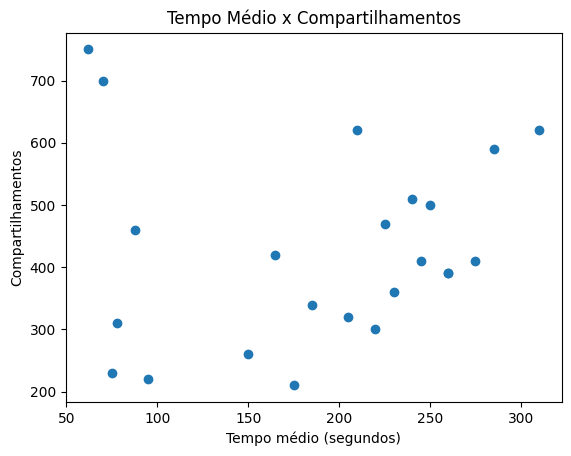

In [18]:
# Gráfico de dispersão: tempo médio x compartilhamentos
plt.scatter(dados["tempo_medio_segundos"], dados["compartilhamentos"])

plt.title("Tempo Médio x Compartilhamentos")
plt.xlabel("Tempo médio (segundos)")
plt.ylabel("Compartilhamentos")
plt.show()

In [19]:
# Correlação entre tempo médio e compartilhamentos
correlacao_tempo = dados["tempo_medio_segundos"].corr(dados["compartilhamentos"])
print("Correlação entre tempo médio e compartilhamentos:", round(correlacao_tempo, 2))

# Correlação entre visualizações e novos assinantes
correlacao_assinantes = dados["visualizacoes"].corr(dados["novos_assinantes"])
print("Correlação entre visualizações e novos assinantes:", round(correlacao_assinantes, 2))

Correlação entre tempo médio e compartilhamentos: 0.1
Correlação entre visualizações e novos assinantes: 0.55


### Análise do gráfico de dispersão: Tempo Médio x Compartilhamentos

Cada ponto representa um conteúdo. Os pontos estão espalhados, sem um padrão claro, e a correlação entre tempo médio e compartilhamentos foi de **0,10**, uma associação muito fraca. Os dois conteúdos com mais compartilhamentos (750 e 700) tiveram pouco mais de um minuto de tempo médio. A correlação entre visualizações e novos assinantes foi de **0,55**, uma associação positiva moderada.

In [20]:
# Questão 3: desempenho editorial
print("Modalidade com mais visualizações:", agrupado_modalidade["visualizacoes"].idxmax())
print("Tipo de conteúdo com maior engajamento:", agrupado_tipo["taxa_engajamento_pct"].idxmax())
print("Conteúdo com mais novos assinantes:", dados.loc[dados["novos_assinantes"].idxmax(), "titulo"])
print("Formato com maior tempo médio:", agrupado_tipo["tempo_medio_segundos"].idxmax())
print("Conteúdo com maior RPM:", dados.loc[dados["rpm"].idxmax(), "titulo"])

Modalidade com mais visualizações: Futebol
Tipo de conteúdo com maior engajamento: Entrevista
Conteúdo com mais novos assinantes: Os melhores lances do fim de semana
Formato com maior tempo médio: Entrevista
Conteúdo com maior RPM: Tecnologia nos boxes reduz tempo de parada


In [21]:
# Questão 4: conteúdos ordenados por visualizações, com a taxa de engajamento
dados[["titulo", "modalidade", "tipo_conteudo", "visualizacoes", "taxa_engajamento_pct"]].sort_values(by="visualizacoes", ascending=False)

,titulo,modalidade,tipo_conteudo,visualizacoes,taxa_engajamento_pct
16,Gol nos acréscimos domina as redes,Futebol,Notícia,75000,5.680000
4,Os melhores lances do fim de semana,Futebol,Vídeo,68000,5.250000
0,Clássico nacional movimenta a rodada,Futebol,Notícia,52000,3.250000
20,Técnico explica mudanças para a decisão,Futebol,Entrevista,47000,5.425532
8,Pressão alta explica vitória no clássico,Futebol,Análise,43000,3.744186
12,A formação de jovens talentos nos clubes,Futebol,Reportagem,39000,4.000000
13,Top 10 jogadas da rodada nacional,Basquete,Vídeo,34000,6.000000
5,Time confirma reforço para a temporada,Basquete,Notícia,31000,3.725806
17,Projeto social forma atletas na periferia,Basquete,Reportagem,30000,4.800000
7,Volta rápida comentada por especialista,Automobilismo,Vídeo,29000,5.034483


# Questões

## Questão 1: Diagnóstico dos dados

**a)** A base tem 24 registros e 15 variáveis.

**b)** Categóricas: `portal`, `titulo`, `modalidade`, `tipo_conteudo` e `turno_publicacao`. Numéricas: `visualizacoes`, `usuarios_unicos`, `tempo_medio_segundos`, `curtidas`, `comentarios`, `compartilhamentos`, `cliques_relacionados`, `novos_assinantes` e `receita_publicitaria`. Temporal: `data_publicacao`.

**c)** Foi encontrado um valor ausente na coluna `tempo_medio_segundos` e uma inconsistência na coluna `modalidade`, em que `Vôlei` aparecia também como `Vôlei `, com espaço no final. A inconsistência foi corrigida com `.str.strip()`.

**d)** O valor ausente pode ter origem em uma falha no registro ou na exportação dos dados. Substituí-lo por zero diria que o conteúdo teve 0 segundo de permanência, o que não é verdade, e diminuiria o tempo médio das entrevistas e do automobilismo. Por isso, o valor foi mantido como ausente.

## Questão 2: Métricas do primeiro conteúdo

Conteúdo: "Clássico nacional movimenta a rodada".

* **Taxa de engajamento:** (1.200 + 180 + 310) ÷ 52.000 × 100 = 3,25%. A cada 100 visualizações, houve cerca de 3 interações.
* **Taxa de recirculação:** 4.100 ÷ 52.000 × 100 = 7,88%. A cada 100 visualizações, cerca de 8 levaram a outro conteúdo.
* **Taxa de conversão:** 145 ÷ 4.100 × 100 = 3,54%. A cada 100 cliques relacionados, cerca de 3,5 viraram assinaturas.
* **RPM:** 4.300 ÷ 52.000 × 1.000 = R$ 82,69. Cada mil visualizações geraram R$ 82,69 de receita publicitária.
* **Frequência média:** 52.000 ÷ 43.000 = 1,21. Cada usuário viu o conteúdo, em média, 1,21 vez.

## Questão 3: Desempenho editorial

1. A modalidade com mais visualizações foi o **futebol**, com 324.000.
2. O tipo de conteúdo com maior engajamento foi a **entrevista**, com 6,20%.
3. O conteúdo com mais novos assinantes foi **"Os melhores lances do fim de semana"**, com 190.
4. O formato com maior tempo médio foi a **entrevista**, com 273,3 segundos.
5. O conteúdo com maior RPM foi **"Tecnologia nos boxes reduz tempo de parada"**, com R$ 174,07.

## Questão 4: Comparação entre alcance e qualidade

**Alto alcance e baixo engajamento:** "Clássico nacional movimenta a rodada", com 52.000 visualizações e taxa de engajamento de 3,25%, a menor da base.

**Menor alcance e maior engajamento:** "Rali mais longo da partida em detalhes", com 24.000 visualizações e taxa de engajamento de 10,00%.

**Hipótese:** a notícia sobre o clássico atrai um público amplo, que lê a informação principal e sai sem interagir. O vídeo de vôlei atrai um público menor e mais interessado no assunto, que interage mais com o conteúdo.

## Questão 5: Associação entre variáveis

A correlação entre tempo médio e compartilhamentos foi de 0,10, uma associação muito fraca. A correlação entre visualizações e novos assinantes foi de 0,55, uma associação positiva moderada.

Uma correlação positiva não comprova causalidade, porque outros fatores podem influenciar as duas variáveis ao mesmo tempo, como a modalidade, o canal, o formato e a importância do jogo. Para provar causa e efeito, seria necessário um teste controlado.

## Questão 6: Insights editoriais

**Insight 1**

**Evidência numérica:** o futebol teve 324.000 visualizações, mas a menor taxa de engajamento (4,70%) e a menor conversão (3,78%). O vôlei teve o menor número de visualizações (125.500), mas a maior taxa de engajamento (9,25%) e a maior conversão (5,34%).

**Interpretação jornalística:** o futebol atrai um público amplo, e o vôlei atrai um público menor, porém mais engajado.

**Relevância editorial:** a quantidade de visualizações, sozinha, não mostra qual cobertura tem o público mais engajado.

**Insight 2**

**Evidência numérica:** a notícia teve o maior número de visualizações entre os tipos de conteúdo (226.000), mas o menor tempo médio (78,0 s) e a menor conversão (3,79%). A reportagem teve a maior conversão (4,90%).

**Interpretação jornalística:** a notícia informa de forma rápida, e a reportagem aprofunda o assunto e mantém o leitor por mais tempo.

**Relevância editorial:** notícias e reportagens têm finalidades diferentes e não devem ser avaliadas pelas mesmas métricas.

**Insight 3**

**Evidência numérica:** o automobilismo teve o maior RPM (R$ 163,76), o dobro do futebol (R$ 81,79), mesmo com menos visualizações.

**Interpretação jornalística:** a receita por visualização depende do público de cada modalidade, e não apenas do volume.

**Relevância editorial:** o automobilismo tem valor comercial, mas a pauta não deve ser decidida apenas pela receita.

## Questão 7: Recomendações

**Recomendação 1**

* **Ação proposta:** incluir nas notícias de futebol links para análises, entrevistas e reportagens relacionadas.
* **Evidência:** o futebol tem o maior número de visualizações, mas a menor recirculação (7,96%) e a menor conversão (3,78%).
* **Resultado esperado:** aumento da recirculação e das novas assinaturas.
* **Métrica de acompanhamento:** taxa de recirculação e taxa de conversão das notícias de futebol.
* **Forma de validação:** comparar notícias com e sem os links em um teste controlado.

**Recomendação 2**

* **Ação proposta:** produzir mais conteúdos aprofundados de vôlei.
* **Evidência:** o vôlei teve a maior taxa de engajamento (9,25%) e a maior conversão (5,34%).
* **Resultado esperado:** mais engajamento e mais novos assinantes.
* **Métrica de acompanhamento:** taxa de engajamento, taxa de conversão e visualizações do vôlei.
* **Forma de validação:** comparar os resultados do vôlei antes e depois da mudança.

## Questão 8: Limitações

Dados adicionais necessários para uma análise mais completa:

1. Origem do tráfego de cada conteúdo (busca, redes sociais, página inicial ou newsletter).
2. Período de medição de cada conteúdo, já que os conteúdos mais antigos tiveram mais tempo para acumular visualizações.
3. Custo de produção de cada conteúdo.

Além disso, a base tem apenas 24 conteúdos e um valor ausente, e os resultados mostram associações, não causas.

### Conclusão

A análise dos 24 conteúdos mostrou que o volume de visualizações não indica, sozinho, o melhor desempenho editorial. O futebol teve o maior número de visualizações, mas a menor taxa de engajamento (4,70%) e a menor conversão (3,78%). O vôlei teve o menor alcance, mas a maior taxa de engajamento (9,25%) e a maior conversão (5,34%). Entre os tipos de conteúdo, a notícia teve mais visualizações, mas o menor tempo médio, e a entrevista teve o maior engajamento e o maior tempo médio. Esses resultados são associações em uma base pequena e não provam causalidade. Os dados ajudam a orientar a decisão editorial, mas não substituem os critérios de relevância, interesse público, diversidade, precisão e responsabilidade.